In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

In [2]:
df = pd.read_csv('height-weight.csv')
df.head()

,Weight,Height
0,45,120
1,58,135
2,48,123
3,60,145
4,70,160


Text(0, 0.5, 'height')

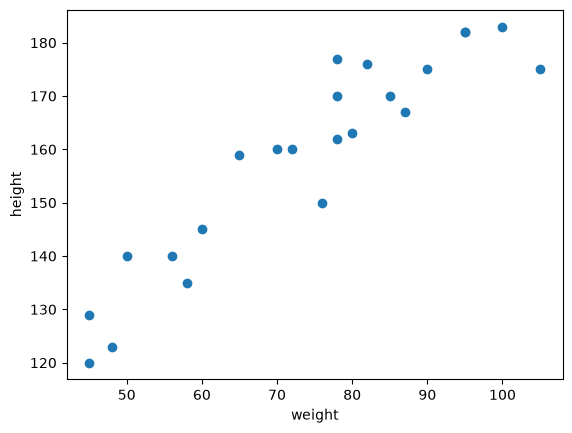

In [ ]:
#check how you dependent and independent features are related
## scatter plot
plt.scatter(df['Weight'],df['Height'])
plt.xlabel("weight")
plt.ylabel("height")
## linear relationship

In [ ]:
## coorelation
df.corr()
# highly coorelated (93%)

,Weight,Height
Weight,1.000000,0.931142
Height,0.931142,1.000000


In [13]:
### divide into independent and dependent feature
x = df[['Weight']] # here the type of x becomes a series not a dataframe
# that's why we use double bracket to get it as a dataframe cause independent feasture should be an 2d array.
y = df['Height'] # but we can use dependent features as a series, cause it is the only one feature. (or it can be 1d array)

In [14]:
x.shape #2d array with 1 column.
# if use single quote then it didn't become in 2d, so always use 2 brackets.

(23, 1)

In [17]:
## Train Test split
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(x,y,test_size=0.25,random_state=42) # in percentage

In [18]:
X_train.shape

(17, 1)

In [21]:
## Standardization
## we have to convert the data into standard form, so that the model can learn better. we have to get mean = 0 and std = 1. so we use standard scaler to do that.
## why we do this? because if it remains in the same form it take time to converge and also it will not give the best result.
## like minimizing the loss function, so that it can converge faster and also it will give the best result. so we have to standardize the data.
from sklearn.preprocessing import StandardScaler
## we have to only do this with independent features, not with dependent features. because the gradient only deals with independent features. so we have to standardize the independent features only.


In [22]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
## Why we used fit transform in the X_train and only tranform in the X_test. (hint : to prevent data leakage and keep the test data isolated)

In [24]:
X_train

array([[-0.87662801],
       [ 1.66773133],
       [ 0.33497168],
       [-1.48242785],
       [ 1.36483141],
       [-1.6641678 ],
       [-0.75546804],
       [-0.1496682 ],
       [ 0.21381171],
       [-1.36126788],
       [-0.99778797],
       [-0.02850823],
       [ 1.06193149],
       [ 0.57729161],
       [ 0.75903157],
       [ 0.88019153],
       [ 0.45613165]])

In [25]:
## Apply Linear regression 
from sklearn.linear_model import LinearRegression

In [26]:
regression = LinearRegression(n_jobs=-1)
regression.fit(X_train,Y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",-1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[17.3]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,156.5
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[4.12]


In [28]:
print(f'Coeff and slope: {regression.coef_}, and the intercept : {regression.intercept_}')
# this is beta 1 in the equation of the BFL and you can see the intercept also in the fitted attribute

Coeff and slope: [17.2982057], and the intercept : 156.47058823529412


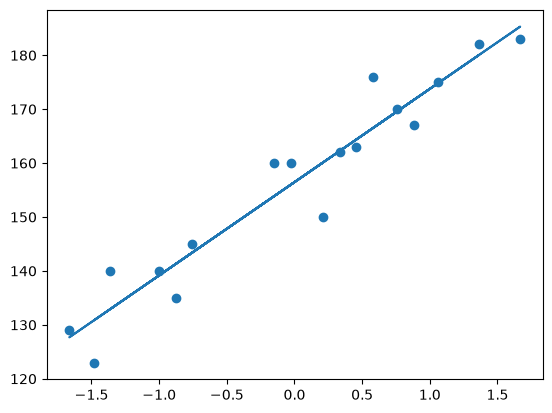

In [31]:
## plot training data plot best fit line
plt.scatter(X_train,Y_train)
plt.plot(X_train,regression.predict(X_train))

In [ ]:
# Prediction of test data
## 1. predicted height output = intercept + coef_(weight)
## 2. y_predicted = 156.470 + 1.26(X_test) 

In [34]:
## prediction for the test data
Y_predicted = regression.predict(X_test)
Y_predicted

array([162.26499721, 162.26499721, 127.68347133, 180.07972266,
       148.64197186, 190.55897293])

In [35]:
## Performance matrix
from sklearn.metrics import mean_absolute_error,mean_squared_error

In [ ]:
mse = mean_squared_error(Y_test,Y_predicted)
mae = mean_absolute_error(Y_test,Y_predicted)
rmse = np.sqrt(mse)
print(mse) # it has penalized many outliers
print(mae)
print(rmse)

114.84069295228699
9.66512588679501
10.716374991212605


In [ ]:
# R square test
# R^2 = 1 - (SSR/SST)
from sklearn.metrics import r2_score

In [43]:
score = r2_score(Y_test,Y_predicted)
score

0.7360826717981276

In [45]:
## OLS linear regression 
import statsmodels.api as sm

In [46]:
model = sm.OLS(Y_train,X_train).fit()

In [48]:
prediction_y = model.predict(X_test)
prediction_y

array([  5.79440897,   5.79440897, -28.78711691,  23.60913442,
        -7.82861638,  34.08838469])

In [50]:
print(model.summary())

                                 OLS Regression Results                                
Dep. Variable:                 Height   R-squared (uncentered):                   0.012
Model:                            OLS   Adj. R-squared (uncentered):             -0.050
Method:                 Least Squares   F-statistic:                             0.1953
Date:                Sun, 01 Nov 2026   Prob (F-statistic):                       0.664
Time:                        22:42:48   Log-Likelihood:                         -110.03
No. Observations:                  17   AIC:                                      222.1
Df Residuals:                      16   BIC:                                      222.9
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

In [52]:
## Since we have been scaled the input weight to reduce the time of finding the global minima
## so if we are going to predict for a perticular weight we have to scale it first
regression.predict(scaler.transform([[72]]))

/Users/akibraza/Desktop/ML/supervised-learning/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([155.97744705])